# Linear Regression Example on MPG Dataset

A note on Model Validation. You can see all of the types of metrics that can be calculated in cross_val_score [here](https://scikit-learn.org/stable/modules/model_evaluation.html).

## Import Libraries & Read in Data

In [1]:
import statsmodels.api as sm
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import seaborn as sns
from sklearn import datasets
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_val_score
from sklearn.metrics import mean_squared_error

In [ ]:
LinearRegression?

In [2]:
url = "http://ddc-datascience.s3.amazonaws.com/auto-mpg.csv"
cars = pd.read_csv(url)
cars.head()


,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin
0,18.0,8,307.0,130.0,3504,12.0,70,1
1,15.0,8,350.0,165.0,3693,11.5,70,1
2,18.0,8,318.0,150.0,3436,11.0,70,1
3,16.0,8,304.0,150.0,3433,12.0,70,1
4,17.0,8,302.0,140.0,3449,10.5,70,1


In [3]:
cars.shape

(398, 8)

## Data Cleaning

In [4]:
cars.describe().transpose()

,count,mean,std,min,25%,50%,75%,max
mpg,398.0,23.514573,7.815984,9.0,17.500,23.0,29.000,46.6
cylinders,398.0,5.454774,1.701004,3.0,4.000,4.0,8.000,8.0
displacement,398.0,193.425879,104.269838,68.0,104.250,148.5,262.000,455.0
horsepower,392.0,104.469388,38.491160,46.0,75.000,93.5,126.000,230.0
weight,398.0,2970.424623,846.841774,1613.0,2223.750,2803.5,3608.000,5140.0
acceleration,398.0,15.568090,2.757689,8.0,13.825,15.5,17.175,24.8
model year,398.0,76.010050,3.697627,70.0,73.000,76.0,79.000,82.0
origin,398.0,1.572864,0.802055,1.0,1.000,1.0,2.000,3.0


In [5]:
# Check to see if there are any NA values
cars.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    392 non-null    float64
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model year    398 non-null    int64  
 7   origin        398 non-null    int64  
dtypes: float64(4), int64(4)
memory usage: 25.0 KB


In [6]:
cars.isnull().sum()*1000

,0
mpg,0
cylinders,0
displacement,0
horsepower,6000
weight,0
acceleration,0
model year,0
origin,0


In [7]:
# Look at rows with NAs
cars[cars['horsepower'].isnull()]


,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin
32,25.0,4,98.0,NaN,2046,19.0,71,1
126,21.0,6,200.0,NaN,2875,17.0,74,1
330,40.9,4,85.0,NaN,1835,17.3,80,2
336,23.6,4,140.0,NaN,2905,14.3,80,1
354,34.5,4,100.0,NaN,2320,15.8,81,2
374,23.0,4,151.0,NaN,3035,20.5,82,1


In [8]:
# Look at horsepower column
cars['horsepower'].describe()


,horsepower
count,392.000000
mean,104.469388
std,38.491160
min,46.000000
25%,75.000000
50%,93.500000
75%,126.000000
max,230.000000


In [16]:
# cars["horsepower"].hist()

In [12]:
# Fill in NAs with mean value
cars_clean = cars.copy()
mean_hp = cars_clean['horsepower'].mean()
# cars_clean['horsepower'].fillna(mean_hp, inplace = True)     # deprecated
cars_clean.fillna({'horsepower': mean_hp}, inplace = True)


In [15]:
# Confirm we don't have NAs anymore
cars_clean.isnull().sum()*1000

,0
mpg,0
cylinders,0
displacement,0
horsepower,0
weight,0
acceleration,0
model year,0
origin,0


## EDA

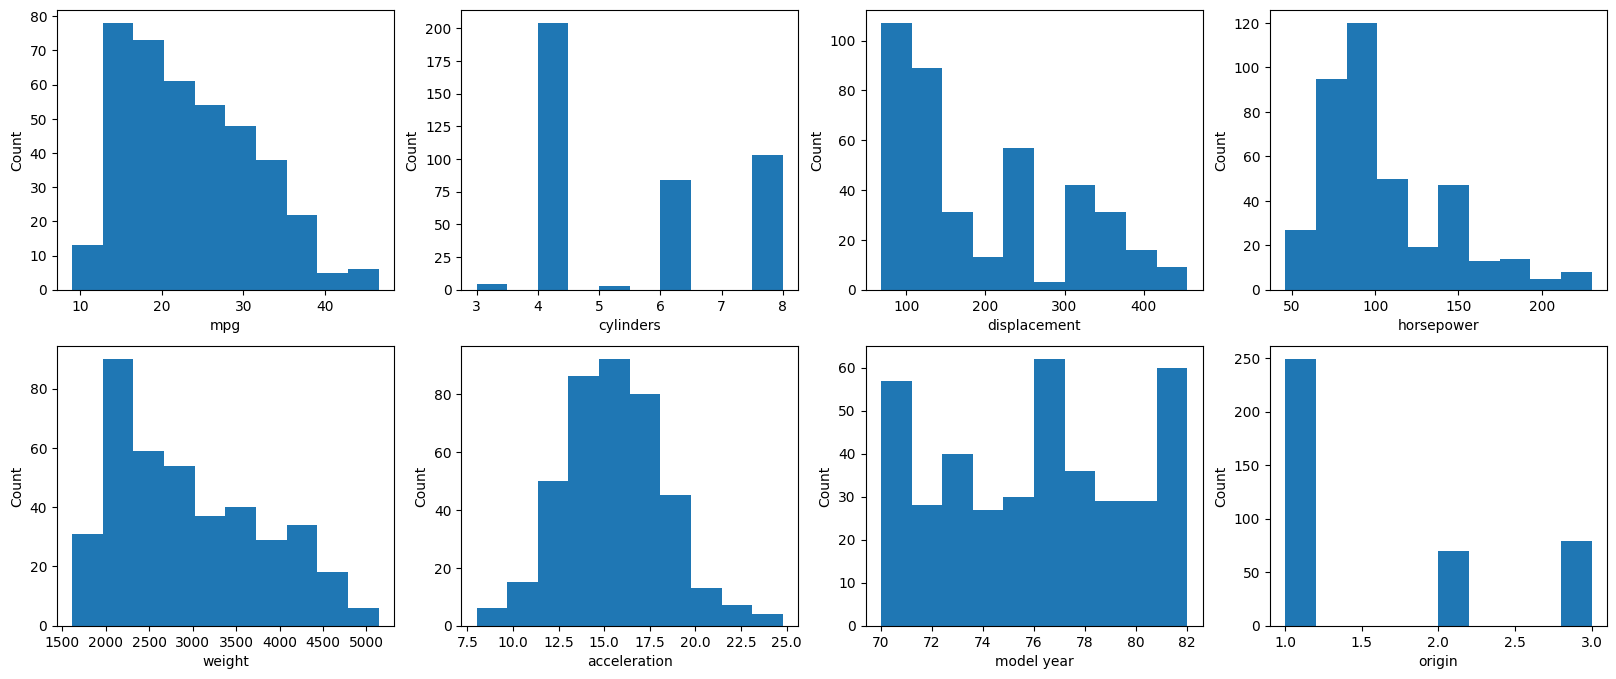

In [17]:
# Let's plot mpg and all of our predictors
fig, axs = plt.subplots(2,4, figsize = (20,8)) # Creating 2x4 subplots because we have 8 columns in our data
column_names = cars_clean.columns
n = 0
for i in range(2): # Loop through rows
  for j in range(4): # Loop through columns
    axs[i,j].hist(cars_clean[column_names[n]])
    axs[i,j].set_xlabel(column_names[n])
    axs[i,j].set_ylabel('Count')
    n = n + 1

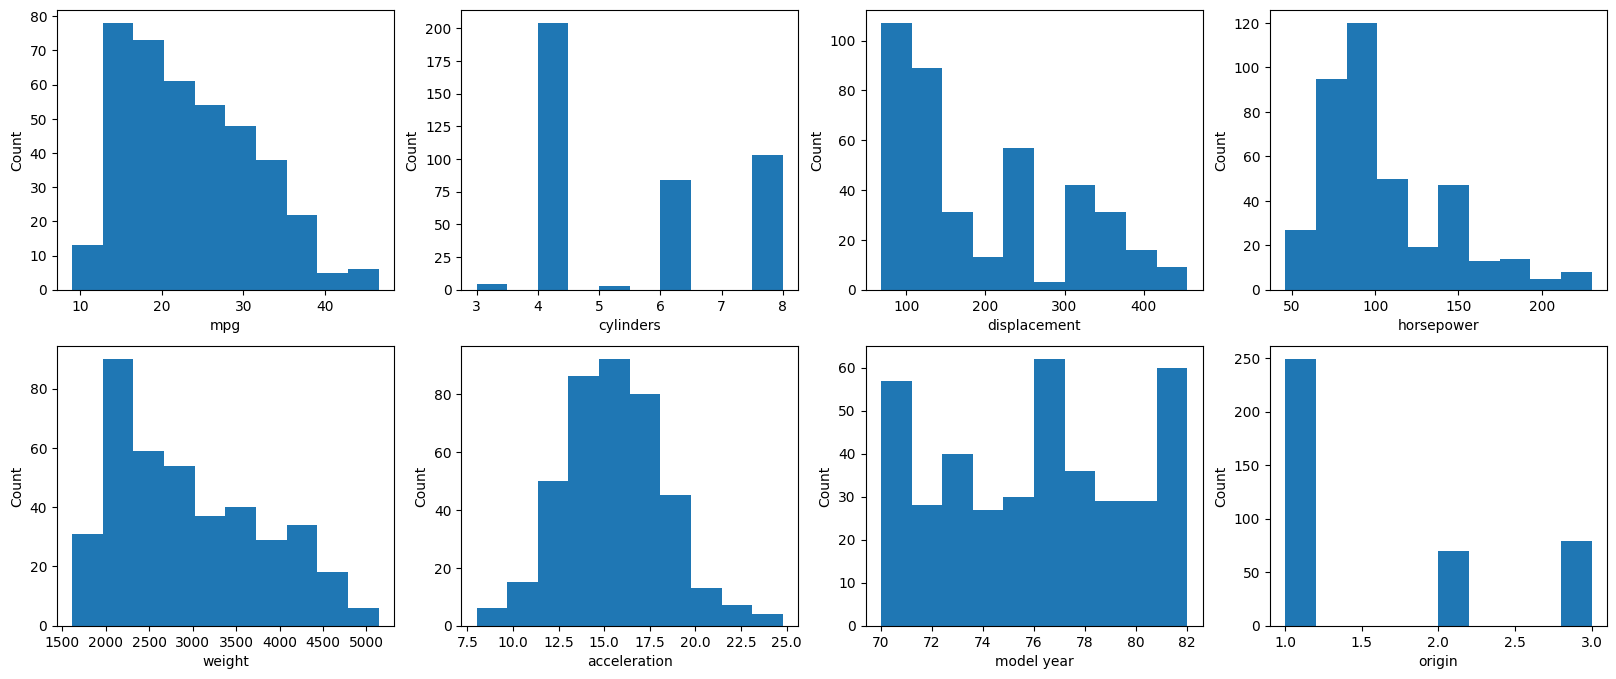

In [18]:
# Let's plot mpg and all of our predictors
fig, subplots = plt.subplots(2,4, figsize = (20,8)) # Creating 2x4 subplots because we have 8 columns in our data
column_names = cars_clean.columns

subplots = subplots.flatten()[:len(column_names)]  # flatten and slice axs
for n, subplot in enumerate(subplots):             # Loop through axs
  subplot.hist(cars_clean[column_names[n]])
  subplot.set_xlabel(column_names[n])
  subplot.set_ylabel('Count')


## What do we notice?
- MPG distribution slightly skewed
- Cylinders and origin are discrete
- Model years only from 1970-1982
- Doesn't appear to have outliers

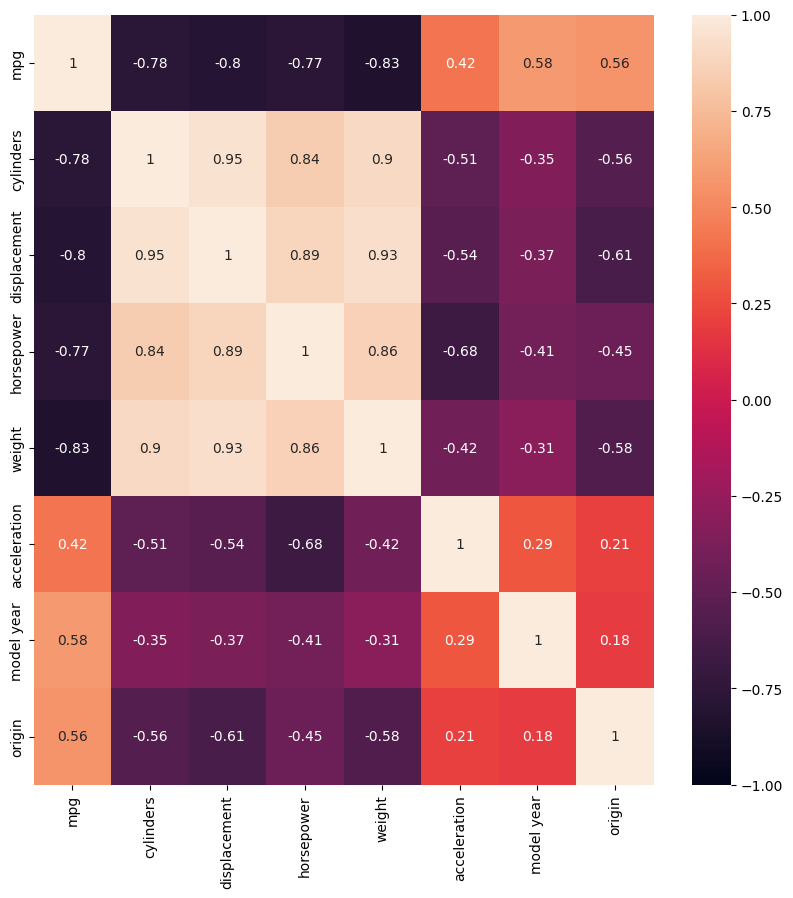

In [19]:
# Let's take a look at a correlation plot
plt.figure(figsize=(10,10))
correlation_matrix = cars_clean.corr().round(2)
sns.heatmap(data=correlation_matrix, annot=True, vmin=-1, vmax=1) ;

In [23]:
corrs = cars_clean.corr().round(2).unstack().abs()
corrs.reset_index()


,level_0,level_1,0
0,mpg,mpg,1.00
1,mpg,cylinders,0.78
2,mpg,displacement,0.80
3,mpg,horsepower,0.77
4,mpg,weight,0.83
...,...,...,...
59,origin,horsepower,0.45
60,origin,weight,0.58
61,origin,acceleration,0.21
62,origin,model year,0.18


In [26]:
corrs = corrs[corrs < 1]
corrs.reset_index()


,level_0,level_1,0
0,mpg,cylinders,0.78
1,mpg,displacement,0.80
2,mpg,horsepower,0.77
3,mpg,weight,0.83
4,mpg,acceleration,0.42
5,mpg,model year,0.58
6,mpg,origin,0.56
7,cylinders,mpg,0.78
8,cylinders,displacement,0.95
9,cylinders,horsepower,0.84


In [28]:
corrs.sort_values(ascending = False)[::2].reset_index()


,level_0,level_1,0
0,displacement,cylinders,0.95
1,displacement,weight,0.93
2,weight,cylinders,0.90
3,horsepower,displacement,0.89
4,weight,horsepower,0.86
5,cylinders,horsepower,0.84
6,mpg,weight,0.83
7,mpg,displacement,0.80
8,cylinders,mpg,0.78
9,mpg,horsepower,0.77


### What do we notice?


*   Many predictors are highly correlated to each other
*   Many predictors are highly correlated with MPG



In [29]:
cars_clean.size

3184

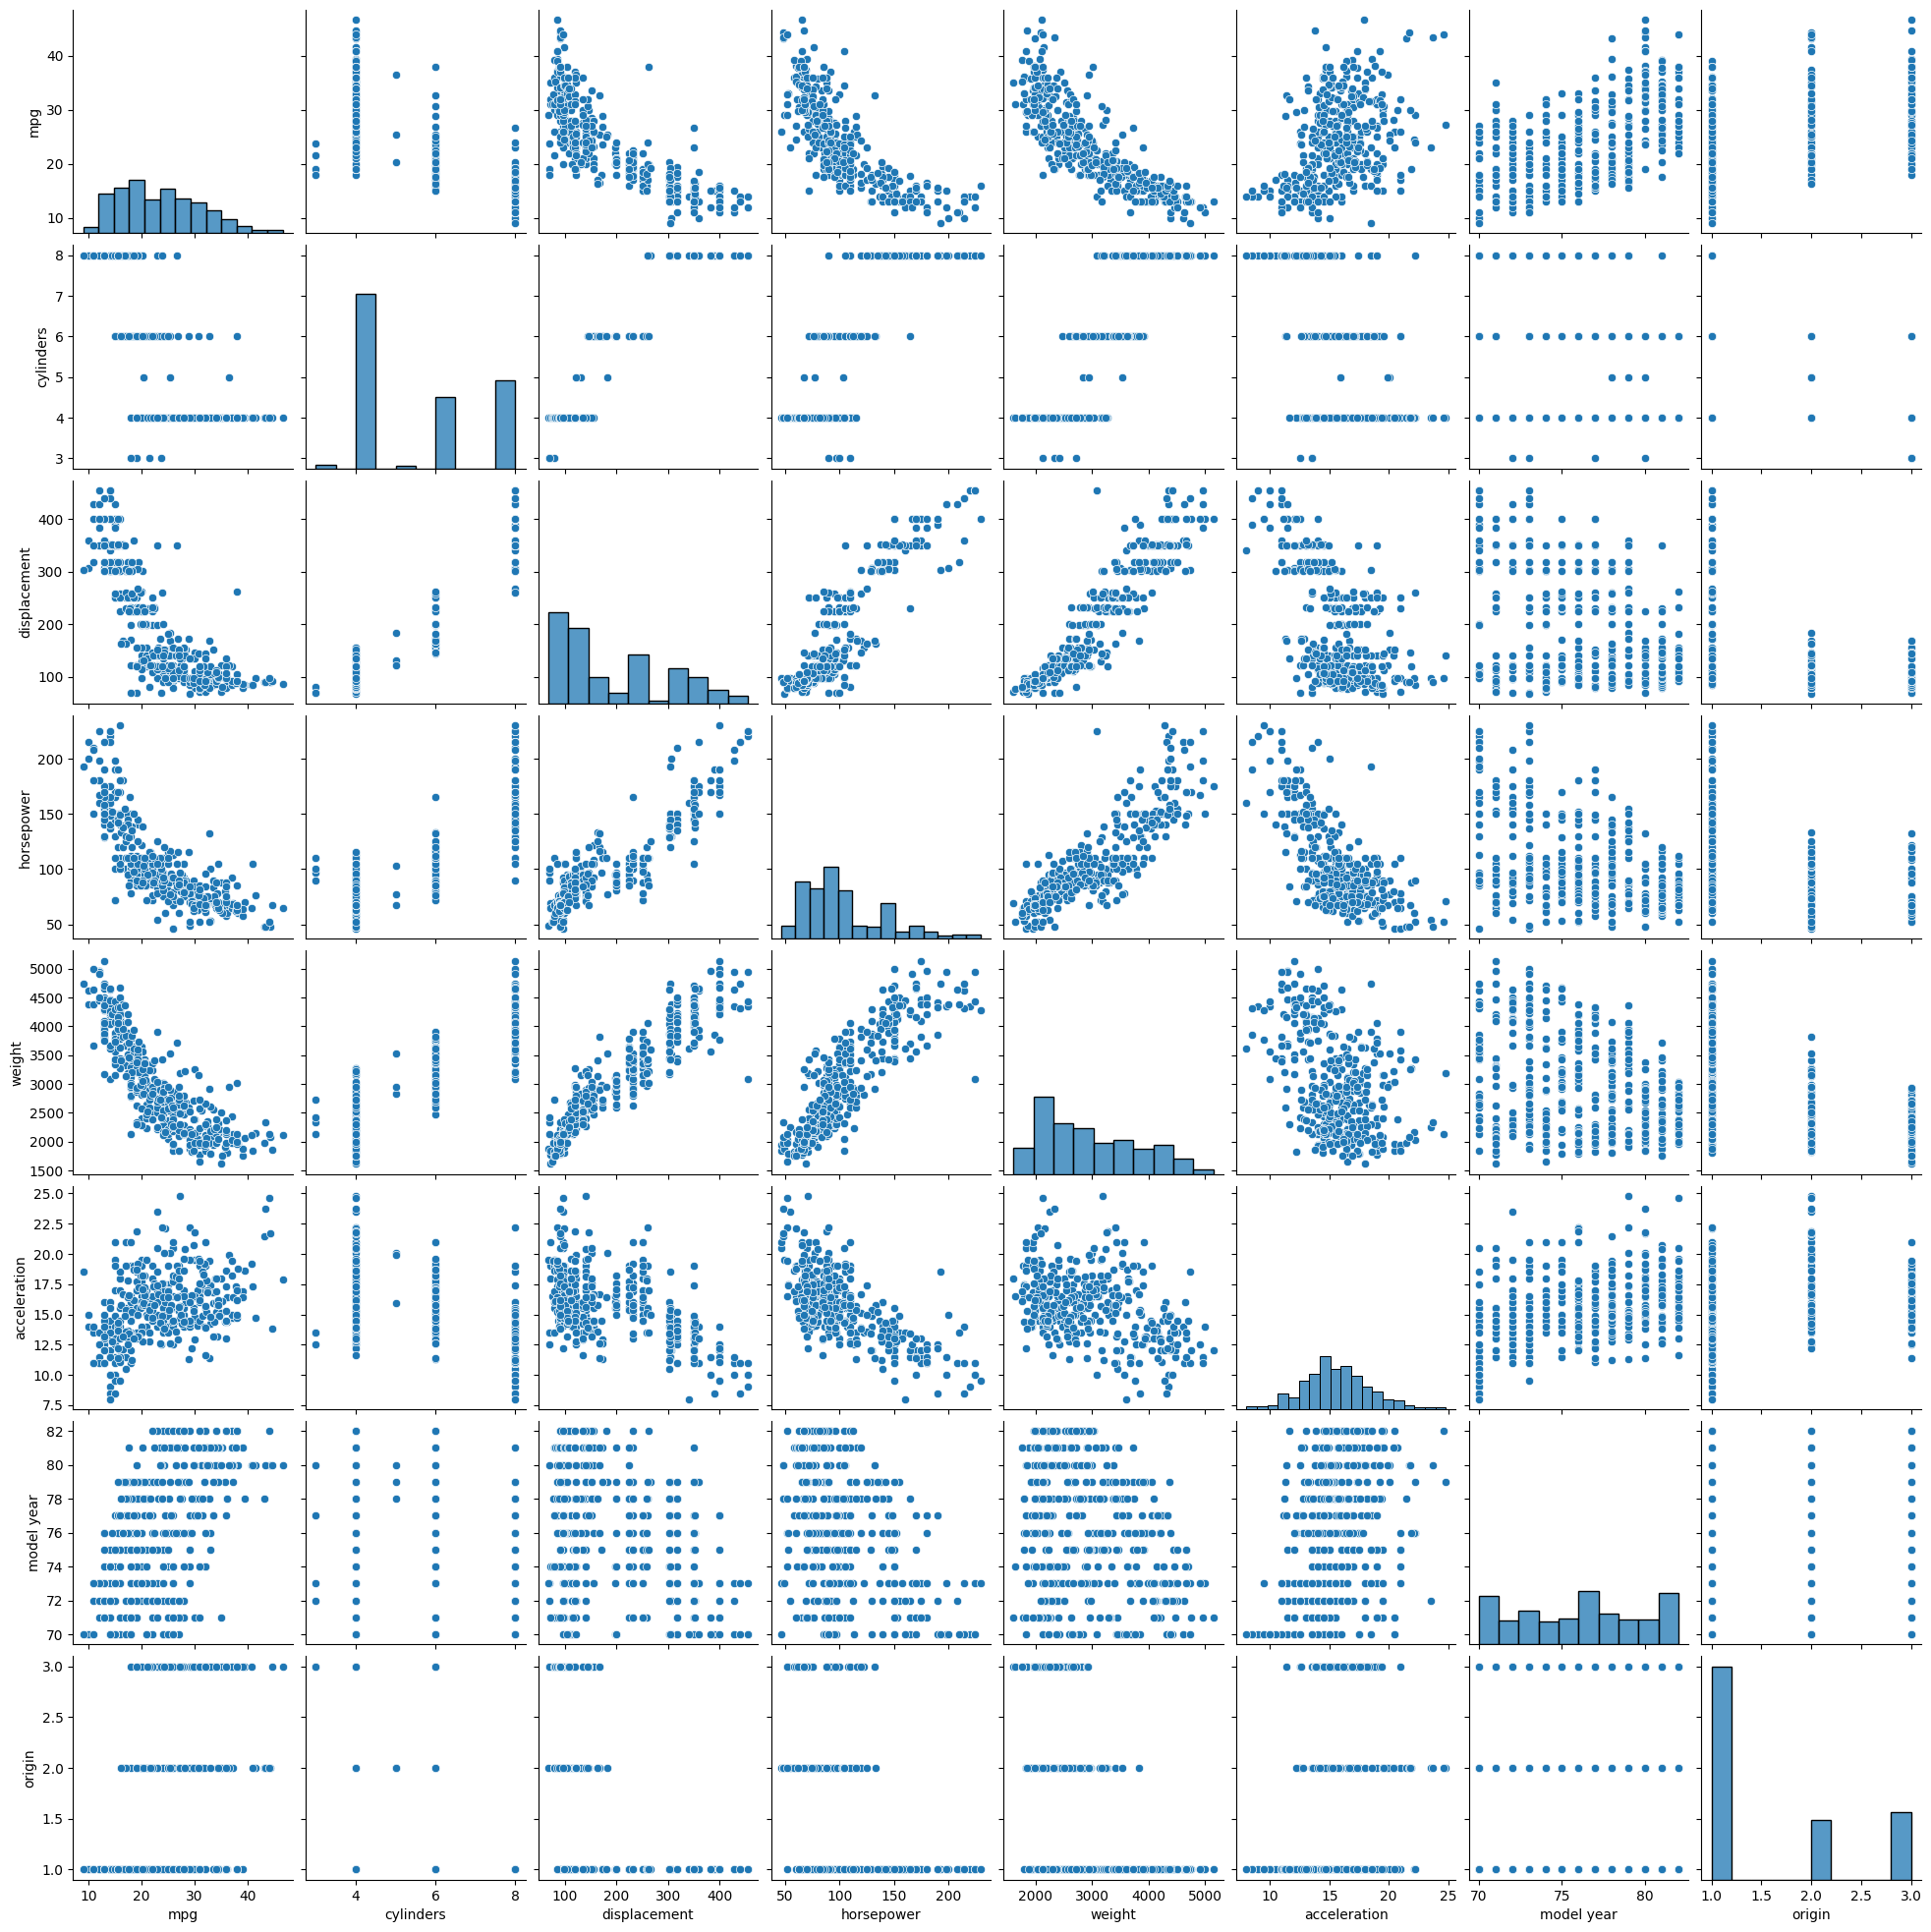

In [30]:
# Let's plot a pairplot
sns.pairplot(cars_clean) ;

### What do we notice?


*   MPG vs weight, displacement, horsepower has a strong relationship - doesn't appear to be quite linear.

## Fit & Assess Our Model

### Using Statsmodels

In [31]:
# First we will break up our data into training and testing sets
X = cars_clean[['weight', 'model year', 'origin', 'displacement']]
X2 = sm.add_constant(X) # add constant so that intercept is estimated
print(X2.head())

y = cars_clean['mpg']
X_train, X_test, y_train, y_test = train_test_split(X2, y, test_size = 0.2, random_state=4)

   const  weight  model year  origin  displacement
0    1.0    3504          70       1         307.0
1    1.0    3693          70       1         350.0
2    1.0    3436          70       1         318.0
3    1.0    3433          70       1         304.0
4    1.0    3449          70       1         302.0


In [32]:
# Fit a linear model using statsmodels
myfit = sm.OLS(y_train, X_train).fit()
myfit.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                    mpg   R-squared:                       0.810
Model:                            OLS   Adj. R-squared:                  0.807
Method:                 Least Squares   F-statistic:                     333.0
Date:                Tue, 23 Jun 2026   Prob (F-statistic):          2.13e-111
Time:                        16:37:36   Log-Likelihood:                -838.61
No. Observations:                 318   AIC:                             1687.
Df Residuals:                     313   BIC:                             1706.
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
================================================================================
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
const          -16.8775      4.507     -3.745      0.000     -25.744      -8.011
weight          -0.0073      0.001    -11.006      0.000      -0.009      -0.006
model year       0.7576      0.055     13.716      0.000       0.649       0.866
origin           1.3219      0.309      4.283      0.000       0.715       1.929
displacement     0.0127      0.006      2.225      0.027       0.001       0.024
==============================================================================
Omnibus:                       36.805   Durbin-Watson:                   2.109
Prob(Omnibus):                  0.000   Jarque-Bera (JB):               71.443
Skew:                           0.638   Prob(JB):                     3.06e-16
Kurtosis:                       4.941   Cond. No.                     7.30e+04
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 7.3e+04. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

### Using Sklearn

In [33]:
# First we will break up our data into training and testing sets
X = cars_clean[['weight', 'model year', 'origin', 'displacement']]
y = cars_clean['mpg']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state=4)

In [34]:
# Fit a linear model using Sklearn
model = LinearRegression()
myfit2 = model.fit(X_train, y_train)

( myfit2.intercept_, myfit2.coef_ )


(np.float64(-16.877512158363917),
 array([-0.00731127,  0.75763738,  1.32186922,  0.01270501]))

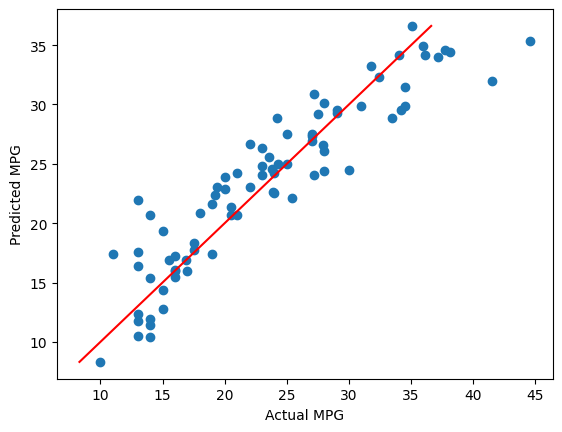

In [35]:
# See how well our model performs on our test data
y_pred = myfit2.predict(X_test)
plt.scatter(y_test, y_pred)
plt.plot([min(y_pred), max(y_pred)],[min(y_pred), max(y_pred)], c='red')
plt.xlabel('Actual MPG')
plt.ylabel('Predicted MPG') ;

In [36]:
list(zip(y_test,y_pred))[:10]

[(31.8, np.float64(33.252619036708296)),
 (14.0, np.float64(11.413800947977492)),
 (21.0, np.float64(24.269383763847504)),
 (38.1, np.float64(34.44126226305251)),
 (18.0, np.float64(20.840806967875796)),
 (23.8, np.float64(24.584867606549263)),
 (44.6, np.float64(35.32940158637827)),
 (36.0, np.float64(34.946629509602474)),
 (20.5, np.float64(20.676210093533886)),
 (30.0, np.float64(24.470536762939627))]

In [37]:
mean_squared_error?

In [38]:
# Calculate root mean squared error on test data
rmse = mean_squared_error(y_test, y_pred)**0.5
print(f"RMSE: {rmse}")

RMSE: 3.1637943296345363


In [39]:
cross_val_score?

In [40]:
# Use cross validation to assess model performance
results = cross_val_score(model, X, y, scoring='neg_root_mean_squared_error', cv = 10)
rmse = abs(results.mean())
print(f"CV RMSE: {rmse}")

CV RMSE: 3.3914281184489696


#### Repeat, but this time scale the features using the StandardScaler ( Z-score ).

In [41]:
# scale the features using the StandardScaler ( Z-score )
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size = 0.2, random_state=4)

In [42]:
X

,weight,model year,origin,displacement
0,3504,70,1,307.0
1,3693,70,1,350.0
2,3436,70,1,318.0
3,3433,70,1,304.0
4,3449,70,1,302.0
...,...,...,...,...
393,2790,82,1,140.0
394,2130,82,2,97.0
395,2295,82,1,135.0
396,2625,82,1,120.0


In [43]:
X_scaled

array([[ 0.63086987, -1.62742629, -0.71514478,  1.0906037 ],
       [ 0.85433297, -1.62742629, -0.71514478,  1.5035143 ],
       [ 0.55047045, -1.62742629, -0.71514478,  1.19623199],
       ...,
       [-0.79858454,  1.62198339, -0.71514478, -0.56103873],
       [-0.40841088,  1.62198339, -0.71514478, -0.70507731],
       [-0.29608816,  1.62198339, -0.71514478, -0.71467988]])

In [44]:
pd.DataFrame(X_scaled).describe().transpose()

,count,mean,std,min,25%,50%,75%,max
0,398.0,-1.606755e-16,1.001259,-1.604943,-0.882827,-0.197362,0.753834,2.565185
1,398.0,-1.642461e-15,1.001259,-1.627426,-0.815074,-0.002721,0.809631,1.621983
2,398.0,-5.355850e-17,1.001259,-0.715145,-0.715145,-0.715145,0.533222,1.781589
3,398.0,-1.785283e-17,1.001259,-1.204411,-0.856318,-0.431404,0.658488,2.511784


In [45]:
# Fit a linear model using Sklearn
model = LinearRegression()
myfit2 = model.fit(X_train, y_train)

(
myfit2.intercept_,
myfit2.coef_
)


(np.float64(23.52958032572574),
 array([-6.18370168,  2.79793854,  1.0588789 ,  1.32308436]))

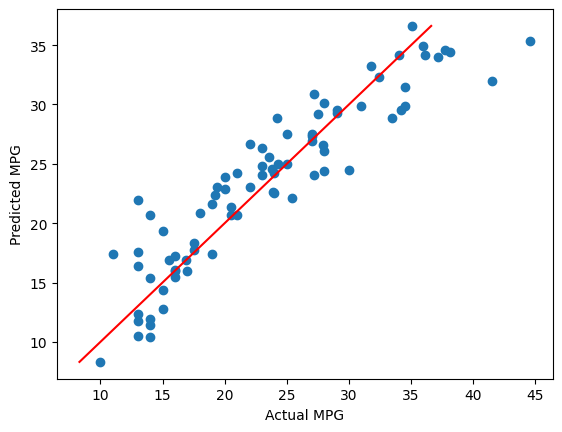

In [46]:
# See how well our model performs on our test data
y_pred = myfit2.predict(X_test)
plt.scatter(y_test, y_pred)
plt.plot([min(y_pred), max(y_pred)],[min(y_pred), max(y_pred)], c='red')
plt.xlabel('Actual MPG')
plt.ylabel('Predicted MPG') ;

In [47]:
list(zip(y_test,y_pred))[:10]

[(31.8, np.float64(33.25261903670828)),
 (14.0, np.float64(11.413800947977514)),
 (21.0, np.float64(24.269383763847493)),
 (38.1, np.float64(34.44126226305249)),
 (18.0, np.float64(20.840806967875796)),
 (23.8, np.float64(24.58486760654926)),
 (44.6, np.float64(35.32940158637825)),
 (36.0, np.float64(34.94662950960247)),
 (20.5, np.float64(20.676210093533882)),
 (30.0, np.float64(24.470536762939624))]

In [48]:
# Calculate root mean squared error on test data
rmse = mean_squared_error(y_test, y_pred)**0.5
print(f"RMSE: {rmse}")

RMSE: 3.1637943296345377


In [49]:
# Use cross validation to assess model performance - scaled
results = cross_val_score(model, X_scaled, y, scoring='neg_root_mean_squared_error', cv = 10)
rmse = abs(results.mean())
print(f"CV RMSE: {rmse}")

CV RMSE: 3.3914281184489594


## Residual Analysis

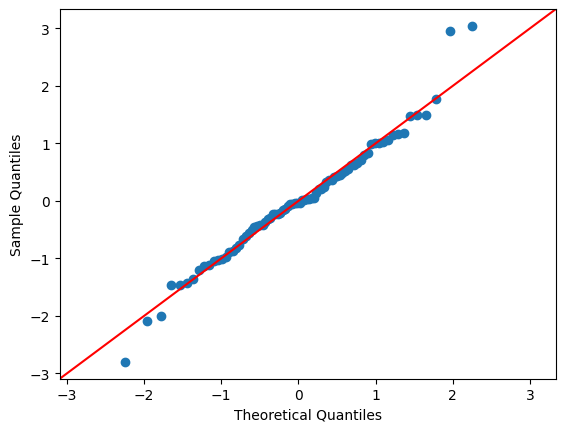

In [50]:
# QQ Plot - Residuals are normally distributed
res = y_test - y_pred
sm.qqplot(res, fit=True, line="45") ;

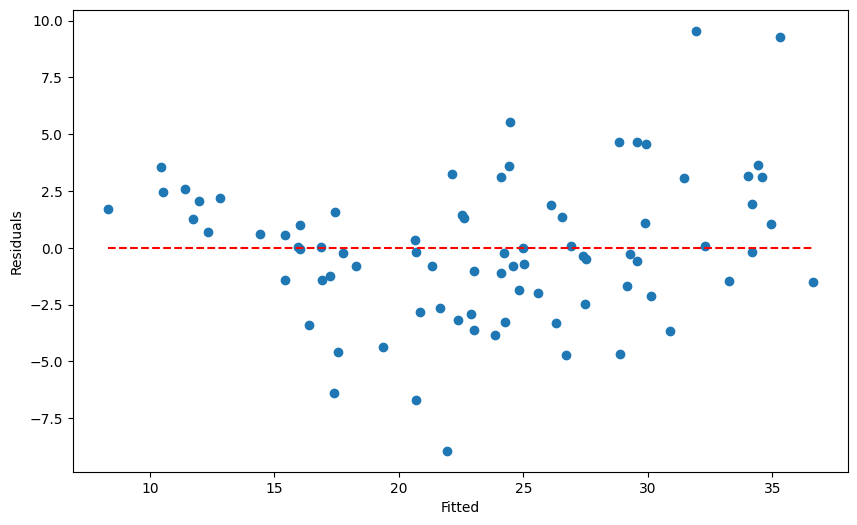

In [51]:
# Residuals vs Fitted (Predicted) Values - Constant variance
plt.figure(figsize = (10,6))
plt.scatter(y_pred, res)
plt.xlabel("Fitted")
plt.ylabel("Residuals")
plt.hlines(0, min(y_pred), max(y_pred), colors = 'red', linestyles = 'dashed') ;

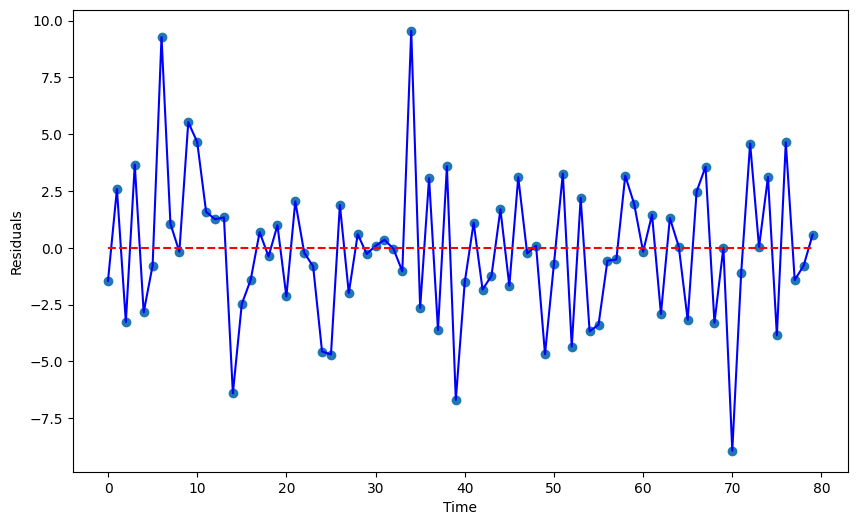

In [52]:
# Residuals vs Time - indepedence
plt.figure(figsize = (10,6))
plt.scatter(range(len(res)), res)
plt.plot(range(len(res)), res, 'b')
plt.xlabel("Time")
plt.ylabel("Residuals")
plt.hlines(0, min(range(len(res))), max(range(len(res))), colors = 'red', linestyles = 'dashed') ;